<a href="https://colab.research.google.com/github/hugolo000/DigitalImage_PROJECT/blob/main/notebooks/02_image_preprocessing_ip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
# Install / upgrade dependencies (Colab usually ships an older albumentations)
!pip install -q -U albumentations opencv-python-headless


2

In [14]:
import os
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

# Same download logic as notebook 01 (each Colab runtime starts empty)
DATASET_URL = "https://github.com/alexgkendall/SegNet-Tutorial/archive/refs/heads/master.zip"
DATA_DIR = Path("./data")
RAW_ZIP_PATH = DATA_DIR / "camvid_raw.zip"
EXTRACTED_DIR = DATA_DIR / "extracted"

DATA_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_ZIP_PATH.exists():
    print("[INFO] Downloading CamVid dataset...")
    urllib.request.urlretrieve(DATASET_URL, RAW_ZIP_PATH)
if not EXTRACTED_DIR.exists():
    print("[INFO] Unzipping dataset files...")
    with zipfile.ZipFile(RAW_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACTED_DIR)

BASE_DIR = (EXTRACTED_DIR / "SegNet-Tutorial-master").resolve()

def load_camvid_split(txt_filename: str, base_dir: Path) -> pd.DataFrame:
    """
    Parses a CamVid split text file keeping only the parent folder and file name,
    ignoring the hardcoded absolute paths of the original .txt.
    """
    txt_path = base_dir / "CamVid" / txt_filename
    image_paths, mask_paths = [], []

    with open(txt_path, "r") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 2:
                img_p, mask_p = Path(parts[0]), Path(parts[1])
                img_abs = (base_dir / "CamVid" / img_p.parts[-2] / img_p.parts[-1]).resolve()
                mask_abs = (base_dir / "CamVid" / mask_p.parts[-2] / mask_p.parts[-1]).resolve()
                if img_abs.exists() and mask_abs.exists():
                    image_paths.append(str(img_abs))
                    mask_paths.append(str(mask_abs))
                else:
                    print(f"[WARNING] File not found: {img_abs}")

    return pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths})

df_train = load_camvid_split("train.txt", BASE_DIR)
df_val = load_camvid_split("val.txt", BASE_DIR)
df_test = load_camvid_split("test.txt", BASE_DIR)

assert len(df_train) > 0, "df_train is empty: check the extracted folder structure"
print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")


[INFO] Downloading CamVid dataset...
[INFO] Unzipping dataset files...
Train: 367 | Val: 101 | Test: 233


In [15]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Define standard target dimensions for the model input
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256

def get_train_transforms():
    """
    Data augmentation and preprocessing pipeline for training images and masks.
    Includes spatial transformations, brightness adjustments, and blurring.
    """
    return A.Compose([
        # 1. Preprocessing: Resize image and mask to fixed target resolution
        A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),

        # 2. Augmentation Method 1: Random Horizontal Flip (50% probability)
        A.HorizontalFlip(p=0.5),

        # 3. Augmentation Method 2: Random Brightness & Contrast adjustment
        A.RandomBrightnessContrast(p=0.2),

        # 4. Augmentation Method 3: Gaussian Blur filter for noise/smoothing
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),

        # 5. Normalization and conversion to PyTorch Tensor
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], is_check_shapes=False)

def get_valid_transforms():
    """
    Minimal preprocessing pipeline for validation and testing sets (no random augmentations).
    """
    return A.Compose([
        A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], is_check_shapes=False)

print("Augmentation pipelines successfully defined.")

Augmentation pipelines successfully defined.


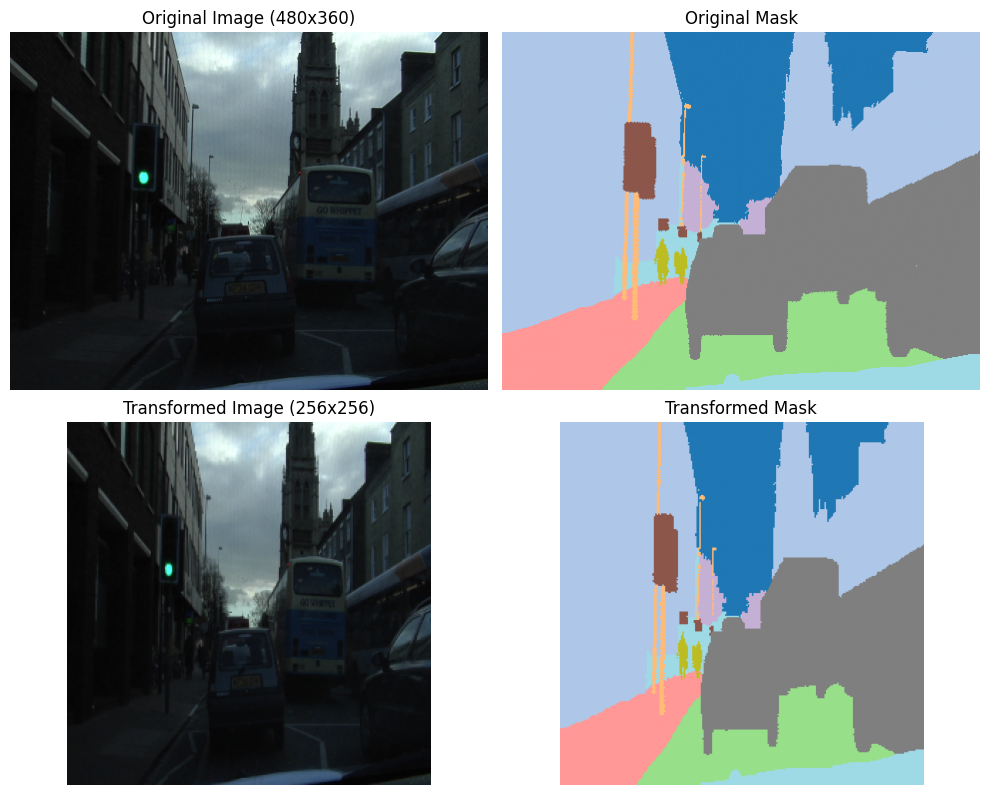

In [16]:
# Select a sample pair from df_train (built in the data cell above)
sample_img_path = df_train.iloc[0]['image_path']
sample_mask_path = df_train.iloc[0]['mask_path']

# Read original RGB image and grayscale mask
image = cv2.imread(sample_img_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
mask = cv2.imread(sample_mask_path, cv2.IMREAD_GRAYSCALE)

# Apply training augmentations
transform = get_train_transforms()
transformed = transform(image=image, mask=mask)
transformed_image = transformed['image']
transformed_mask = transformed['mask']

# Plot Before and After comparison
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].imshow(image)
axes[0, 0].set_title(f"Original Image ({image.shape[1]}x{image.shape[0]})")
axes[0, 0].axis('off')

axes[0, 1].imshow(mask, cmap='tab20')
axes[0, 1].set_title("Original Mask")
axes[0, 1].axis('off')

# Revert normalization for visualization of transformed image tensor
disp_img = transformed_image.permute(1, 2, 0).numpy()
disp_img = disp_img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])

axes[1, 0].imshow(disp_img.clip(0, 1))
axes[1, 0].set_title(f"Transformed Image ({IMAGE_WIDTH}x{IMAGE_HEIGHT})")
axes[1, 0].axis('off')

axes[1, 1].imshow(transformed_mask.numpy(), cmap='tab20')
axes[1, 1].set_title("Transformed Mask")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

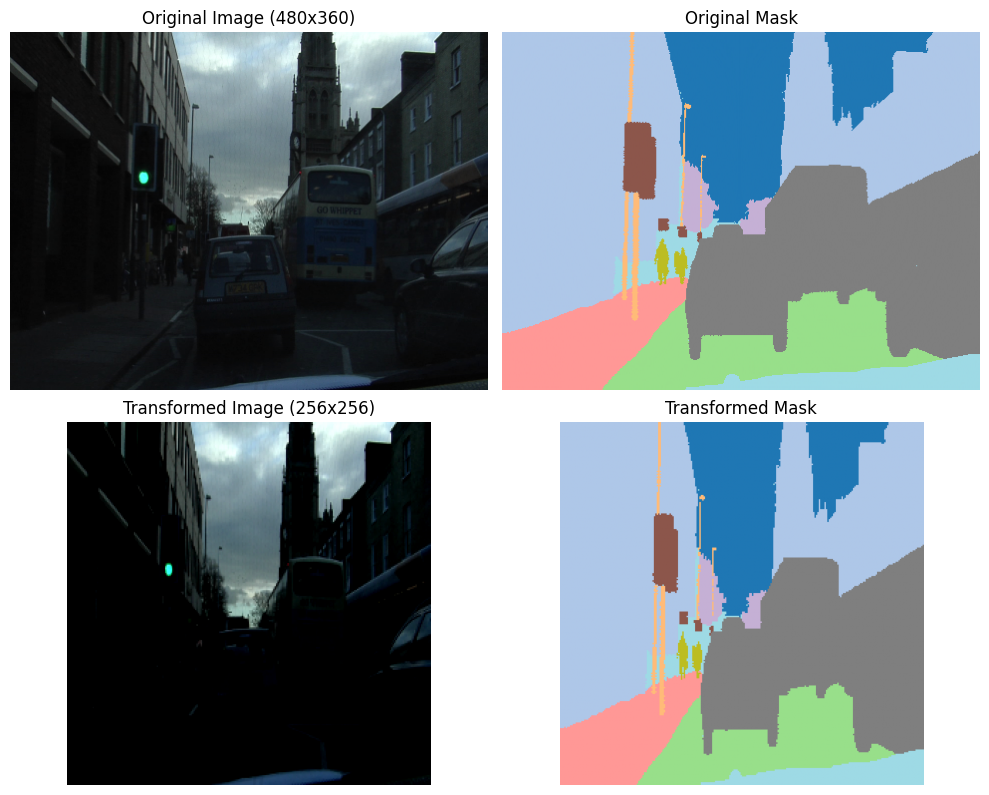

In [17]:
# Select a sample pair from df_train created in notebook 01
sample_img_path = df_train.iloc[0]['image_path']
sample_mask_path = df_train.iloc[0]['mask_path']

# Read original RGB image and grayscale mask
image = cv2.imread(sample_img_path)
assert image is not None, f"Could not read image: {sample_img_path}"
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
mask = cv2.imread(sample_mask_path, cv2.IMREAD_GRAYSCALE)
assert mask is not None, f"Could not read mask: {sample_mask_path}"

# Apply training augmentations
transform = get_train_transforms()
transformed = transform(image=image, mask=mask)
transformed_image = transformed['image']
transformed_mask = transformed['mask']

# Plot Before and After comparison
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].imshow(image)
axes[0, 0].set_title(f"Original Image ({image.shape[1]}x{image.shape[0]})")
axes[0, 0].axis('off')

axes[0, 1].imshow(mask, cmap='tab20')
axes[0, 1].set_title("Original Mask")
axes[0, 1].axis('off')

# Revert normalization for visualization of transformed image tensor
import numpy as np
disp_img = transformed_image.permute(1, 2, 0).numpy()
disp_img = disp_img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])

axes[1, 0].imshow(disp_img.clip(0, 1))
axes[1, 0].set_title(f"Transformed Image ({IMAGE_WIDTH}x{IMAGE_HEIGHT})")
axes[1, 0].axis('off')

axes[1, 1].imshow(transformed_mask.numpy(), cmap='tab20')
axes[1, 1].set_title("Transformed Mask")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()